<a href="https://colab.research.google.com/github/abhinavdodiyar/Weather-Dataset-analysis-/blob/main/Spam_Ham_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:

print("Step 3 test successful")

Step 3 test successful


In [29]:

import pandas as pd
import urllib.request
import zipfile
from io import BytesIO

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = urllib.request.urlopen(url)
dataset_zip = zipfile.ZipFile(BytesIO(response.read()))

with dataset_zip.open("SMSSpamCollection") as file:
    df = pd.read_csv(
        file,
        sep="\t",
        header=None,
        names=["label", "message"]
    )

print("Dataset loaded successfully!")
print("Total messages:", len(df))
print(df.head())

Dataset loaded successfully!
Total messages: 5572
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [30]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass percentages:")
print(
    (df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

# Remove any incomplete or duplicate records
df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates()

# Keep only the expected two labels
df = df[df["label"].isin(["ham", "spam"])]

# Remove empty messages
df = df[df["message"].str.strip().ne("")]

df = df.reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)

Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

Cleaned dataset shape: (5169, 2)


In [31]:

from sklearn.model_selection import train_test_split

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [32]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix: (4135, 31151)
Testing matrix: (1034, 31151)


In [33]:

from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


Model Accuracy: 95.36%

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.78       131

    accuracy                           0.95      1034
   macro avg       0.97      0.82      0.87      1034
weighted avg       0.96      0.95      0.95      1034



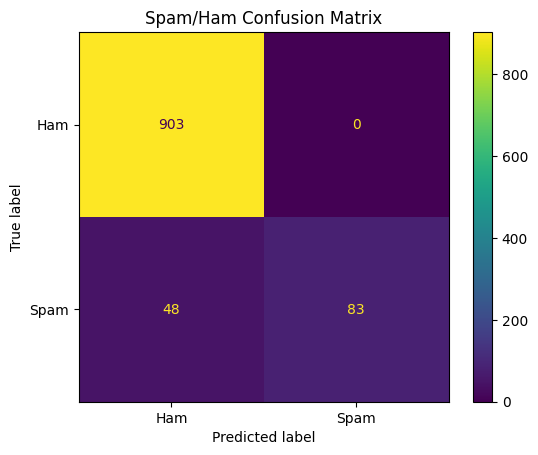

In [34]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot()
plt.title("Spam/Ham Confusion Matrix")
plt.show()

In [36]:

def predict_message(message):
    message_features = vectorizer.transform([message])
    prediction = model.predict(message_features)[0]

    print("\nMessage:", message)

    if prediction == "spam":
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM (likely legitimate)")

    probabilities = model.predict_proba(message_features)[0]
    spam_index = list(model.classes_).index("spam")

    print(
        f"Model's spam probability estimate: "
        f"{probabilities[spam_index]:.2%}"
    )


predict_message(
    "Congratulations! You won a free prize. Call now!"
)

predict_message(
    "Hi, are we meeting for lunch today?"
)

predict_message(
    "URGENT! Claim your free cash reward now"
)


Message: Congratulations! You won a free prize. Call now!
Prediction: SPAM
Model's spam probability estimate: 67.52%

Message: Hi, are we meeting for lunch today?
Prediction: HAM (likely legitimate)
Model's spam probability estimate: 0.54%

Message: URGENT! Claim your free cash reward now
Prediction: SPAM
Model's spam probability estimate: 76.23%


In [37]:

import joblib

joblib.dump(model, "spam_classifier.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Saved model and vectorizer successfully!")

Saved model and vectorizer successfully!


In [38]:

print("=" * 40)
print("SPAM/HAM CLASSIFIER - PROJECT SUMMARY")
print("=" * 40)

print("Dataset: SMS Spam Collection")
print("Algorithm: Multinomial Naive Bayes")
print("Feature extraction: TF-IDF")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Test accuracy: {accuracy:.2%}")

print("\nDetailed evaluation:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    )
)

print("Project completed!")

SPAM/HAM CLASSIFIER - PROJECT SUMMARY
Dataset: SMS Spam Collection
Algorithm: Multinomial Naive Bayes
Feature extraction: TF-IDF
Training samples: 4135
Testing samples: 1034
Test accuracy: 95.36%

Detailed evaluation:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.78       131

    accuracy                           0.95      1034
   macro avg       0.97      0.82      0.87      1034
weighted avg       0.96      0.95      0.95      1034

Project completed!
